<a href="https://colab.research.google.com/github/nilaynishant/acrs/blob/main/06_ML_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# Notebook 2 – Machine Learning Classification
### GeoAI for Future Earth | ACRS Training Workshop 2026

**Learning objectives:**
- Prepare training / test data with stratified splitting and feature scaling
- Train three classifiers: **SVM**, **Random Forest**, **XGBoost**
- Optimise hyperparameters with **GridSearchCV**
- Perform accuracy assessment (OA, Kappa, confusion matrix, classification report)
- Generate and visualise a LULC classification map


## 0 · Setup

In [ ]:
%%capture
!pip install rioxarray geopandas xarray matplotlib numpy pandas seaborn scikit-learn xgboost


## 1 · Data Preparation
*(Reproduces the preprocessing from Notebook 1 – run once per session)*

In [ ]:
import os, subprocess, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import rioxarray as rxr
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

# ── Clone repository ──────────────────────────────────────────
REPO_URL = 'https://github.com/nilaynishant/AIMLTutorial.git'
REPO_DIR = '/content/AIMLTutorial'
if not os.path.exists(REPO_DIR):
    subprocess.run(['git', 'clone', '--depth=1', REPO_URL, REPO_DIR],
                   capture_output=True, check=True)
    print("Repository cloned.")
else:
    print("Repository already present.")

RASTER_PATH = f'{REPO_DIR}/Data/Sentinel2_Agartala.tif'
POINTS_PATH = f'{REPO_DIR}/Data/Training.gpkg'

# ── Load raster and assign band names ────────────────────────
# Bands in the TIF: Band1=B8A(NIR), Band2=B4(Red), Band3=B3(Green), Band4=B2(Blue)
img = rxr.open_rasterio(RASTER_PATH).assign_coords(band=['B8A', 'B4', 'B3', 'B2'])
img_ref = img.astype(float) / 10000.0   # scale DN → surface reflectance

nir, red, green, blue = (img_ref.sel(band=b) for b in ['B8A', 'B4', 'B3', 'B2'])

# ── Spectral indices ──────────────────────────────────────────
ndvi = (nir - red)   / (nir + red)
ndwi = (green - nir) / (green + nir)
savi = 1.5 * (nir - red) / (nir + red + 0.5)
evi  = (2.5 * (nir - red) / (nir + 6*red - 7.5*blue + 1)).clip(-2, 2)

def _band(da, name):
    return da.expand_dims({'band': [name]})

stacked = xr.concat([
    img_ref,
    _band(ndvi, 'NDVI'), _band(ndwi, 'NDWI'),
    _band(savi, 'SAVI'), _band(evi,  'EVI')
], dim='band')

FEATURE_NAMES = stacked.band.values.tolist()
CLASS_MAP = {1: 'Vegetation', 2: 'Builtup', 3: 'Water', 4: 'Agriculture', 5: 'Fallow'}
LULC_COLORS = ['#2ECC71', '#E74C3C', '#3498DB', '#F1C40F', '#95A5A6']

# ── Sample pixel values at training points ────────────────────
gdf = gpd.read_file(POINTS_PATH).to_crs(stacked.rio.crs)
xs = xr.DataArray(gdf.geometry.x.values, dims=['pts'])
ys = xr.DataArray(gdf.geometry.y.values, dims=['pts'])
sampled = stacked.sel(x=xs, y=ys, method='nearest')  # (bands, n_pts)

df = pd.DataFrame(sampled.values.T, columns=FEATURE_NAMES)
df.insert(0, 'label',      gdf['id'].values)
df.insert(1, 'class_name', df['label'].map(CLASS_MAP))

print(f"Features ({len(FEATURE_NAMES)}): {FEATURE_NAMES}")
print(f"Training samples: {len(df)}  |  Classes: {df['label'].nunique()}")
df.head()


Repository cloned.
Features (8): ['B8A', 'B4', 'B3', 'B2', 'NDVI', 'NDWI', 'SAVI', 'EVI']
Training samples: 51  |  Classes: 5


,label,class_name,B8A,B4,B3,B2,NDVI,NDWI,SAVI,EVI
0,1,Vegetation,0.2353,0.0430,0.0569,0.0446,0.690981,-0.610541,0.370615,0.414869
1,1,Vegetation,0.2664,0.0500,0.0601,0.0446,0.683944,-0.631853,0.397599,0.439159
2,1,Vegetation,0.2628,0.0451,0.0577,0.0433,0.707048,-0.639938,0.404196,0.450296
3,1,Vegetation,0.2335,0.0481,0.0613,0.0476,0.658381,-0.584125,0.355809,0.397820
4,1,Vegetation,0.2535,0.0679,0.0795,0.0607,0.577474,-0.522523,0.338934,0.384855


## 2 · Train / Test Split & Feature Scaling

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[FEATURE_NAMES].values
y = df['label'].values

# Stratified 70 / 30 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")

# Scale features to zero mean, unit variance (important for SVM)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print("\nClass distribution in test set:")
for cls, cnt in zip(*np.unique(y_test, return_counts=True)):
    print(f"  {CLASS_MAP[cls]:12s}: {cnt}")


Train: (35, 8)  |  Test: (16, 8)

Class distribution in test set:
  Vegetation  : 3
  Builtup     : 3
  Water       : 3
  Agriculture : 4
  Fallow      : 3


## 3 · Baseline Models (default hyperparameters)

We first train each model with default settings to establish a performance baseline.


In [ ]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

# ── Baseline SVM ───────────────────────────────────────────────
svm_base = SVC(kernel='rbf', random_state=42)
svm_base.fit(X_train_sc, y_train)

# ── Baseline RF ────────────────────────────────────────────────
rf_base = RandomForestClassifier(n_estimators=100, random_state=42)
rf_base.fit(X_train, y_train)

# ── Baseline XGBoost ───────────────────────────────────────────
xgb_base = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss',
                          random_state=42, verbosity=0)
# XGBoost needs labels starting from 0
xgb_base.fit(X_train, y_train - 1)

print("Baseline Accuracy Scores (test set):")
print(f"  SVM     : {accuracy_score(y_test, svm_base.predict(X_test_sc))*100:.1f}%")
print(f"  RF      : {accuracy_score(y_test, rf_base.predict(X_test))*100:.1f}%")
print(f"  XGBoost : {accuracy_score(y_test, xgb_base.predict(X_test)+1)*100:.1f}%")


Baseline Accuracy Scores (test set):
  SVM     : 87.5%
  RF      : 87.5%
  XGBoost : 75.0%


## 4 · Hyperparameter Optimisation with GridSearchCV

GridSearchCV exhaustively searches a parameter grid using cross-validation to find the
combination that maximises the chosen scoring metric.

```
GridSearchCV(estimator, param_grid, cv=5, scoring='accuracy')
```

> **Tip:** With small datasets, use `cv=5` (5-fold stratified cross-validation) to get
> a reliable estimate without overfitting to the validation set.


In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ────────────────────────────────────────────────────────────────
# 4-A  SVM  (GridSearchCV)
# ────────────────────────────────────────────────────────────────
svm_param_grid = {
    'C'      : [0.1, 1, 10, 100],
    'kernel' : ['rbf', 'linear'],
    'gamma'  : ['scale', 'auto', 0.01, 0.1],
}

print("Optimising SVM  … (this may take ~1 min)")
svm_gs = GridSearchCV(SVC(random_state=42), svm_param_grid,
                      cv=cv, scoring='accuracy', n_jobs=-1, verbose=0)
svm_gs.fit(X_train_sc, y_train)

print(f"  Best params : {svm_gs.best_params_}")
print(f"  CV accuracy : {svm_gs.best_score_*100:.1f}%")
best_svm = svm_gs.best_estimator_


Optimising SVM  … (this may take ~1 min)
  Best params : {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
  CV accuracy : 91.4%


In [ ]:
# ────────────────────────────────────────────────────────────────
# 4-B  Random Forest  (GridSearchCV)
# ────────────────────────────────────────────────────────────────
rf_param_grid = {
    'n_estimators'     : [50, 100, 200],
    'max_depth'        : [None, 5, 10, 20],
    'min_samples_split': [2, 5],
    'max_features'     : ['sqrt', 'log2'],
}

print("Optimising Random Forest  … (this may take ~1 min)")
rf_gs = GridSearchCV(RandomForestClassifier(random_state=42), rf_param_grid,
                     cv=cv, scoring='accuracy', n_jobs=-1, verbose=0)
rf_gs.fit(X_train, y_train)

print(f"  Best params : {rf_gs.best_params_}")
print(f"  CV accuracy : {rf_gs.best_score_*100:.1f}%")
best_rf = rf_gs.best_estimator_


Optimising Random Forest  … (this may take ~1 min)
  Best params : {'max_depth': None, 'max_features': 'log2', 'min_samples_split': 2, 'n_estimators': 50}
  CV accuracy : 88.6%


In [ ]:
# ────────────────────────────────────────────────────────────────
# 4-C  XGBoost  (GridSearchCV)
# ────────────────────────────────────────────────────────────────
xgb_param_grid = {
    'n_estimators'  : [50, 100, 200],
    'max_depth'     : [3, 5, 7],
    'learning_rate' : [0.01, 0.1, 0.3],
    'subsample'     : [0.8, 1.0],
}

print("Optimising XGBoost  … (this may take ~2 min)")
xgb_gs = GridSearchCV(
    XGBClassifier(use_label_encoder=False, eval_metric='mlogloss',
                  random_state=42, verbosity=0),
    xgb_param_grid, cv=cv, scoring='accuracy', n_jobs=-1, verbose=0)
xgb_gs.fit(X_train, y_train - 1)           # XGB labels must start at 0

print(f"  Best params : {xgb_gs.best_params_}")
print(f"  CV accuracy : {xgb_gs.best_score_*100:.1f}%")
best_xgb = xgb_gs.best_estimator_


Optimising XGBoost  … (this may take ~2 min)
  Best params : {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 50, 'subsample': 0.8}
  CV accuracy : 85.7%


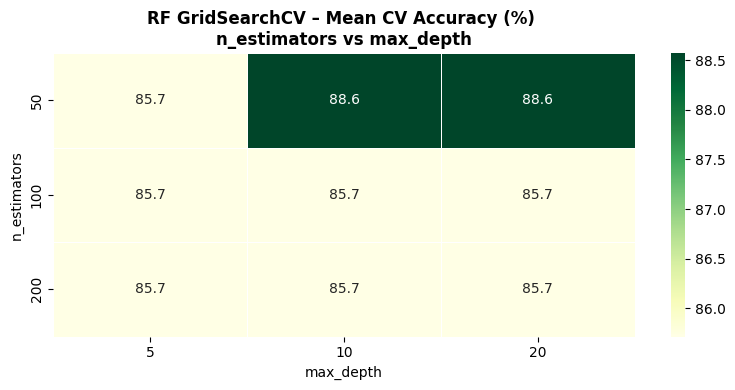

In [ ]:
# Visualise GridSearchCV results for Random Forest
import matplotlib.ticker as mticker

rf_results = pd.DataFrame(rf_gs.cv_results_)
pivot_depth = rf_results.pivot_table(
    index='param_n_estimators', columns='param_max_depth',
    values='mean_test_score', aggfunc='max')

fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(pivot_depth * 100, annot=True, fmt='.1f', cmap='YlGn',
            linewidths=0.5, ax=ax)
ax.set_title('RF GridSearchCV – Mean CV Accuracy (%) \nn_estimators vs max_depth', fontweight='bold')
ax.set_xlabel('max_depth')
ax.set_ylabel('n_estimators')
plt.tight_layout()
plt.show()


## 5 · Accuracy Assessment

In [ ]:
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, cohen_kappa_score)

CLASS_NAMES = [CLASS_MAP[i] for i in sorted(CLASS_MAP)]

def evaluate(name, y_true, y_pred, label_offset=0):
    y_pred_adj = y_pred + label_offset
    oa    = accuracy_score(y_true, y_pred_adj) * 100
    kappa = cohen_kappa_score(y_true, y_pred_adj)
    print(f"\n{'─'*55}")
    print(f" {name}")
    print(f"{'─'*55}")
    print(f" Overall Accuracy : {oa:.1f}%")
    print(f" Cohen's Kappa    : {kappa:.4f}")
    print(classification_report(y_true, y_pred_adj,
                                target_names=CLASS_NAMES, zero_division=0))
    return y_pred_adj

svm_pred = evaluate('SVM  (tuned)', y_test, best_svm.predict(X_test_sc))
rf_pred  = evaluate('RF   (tuned)', y_test, best_rf.predict(X_test))
xgb_pred = evaluate('XGBoost (tuned)', y_test, best_xgb.predict(X_test), label_offset=1)



───────────────────────────────────────────────────────
 SVM  (tuned)
───────────────────────────────────────────────────────
 Overall Accuracy : 81.2%
 Cohen's Kappa    : 0.7659
              precision    recall  f1-score   support

  Vegetation       1.00      0.67      0.80         3
     Builtup       1.00      1.00      1.00         3
       Water       1.00      1.00      1.00         3
 Agriculture       0.67      0.50      0.57         4
      Fallow       0.60      1.00      0.75         3

    accuracy                           0.81        16
   macro avg       0.85      0.83      0.82        16
weighted avg       0.84      0.81      0.81        16


───────────────────────────────────────────────────────
 RF   (tuned)
───────────────────────────────────────────────────────
 Overall Accuracy : 81.2%
 Cohen's Kappa    : 0.7659
              precision    recall  f1-score   support

  Vegetation       0.67      0.67      0.67         3
     Builtup       1.00      1.00      1.0

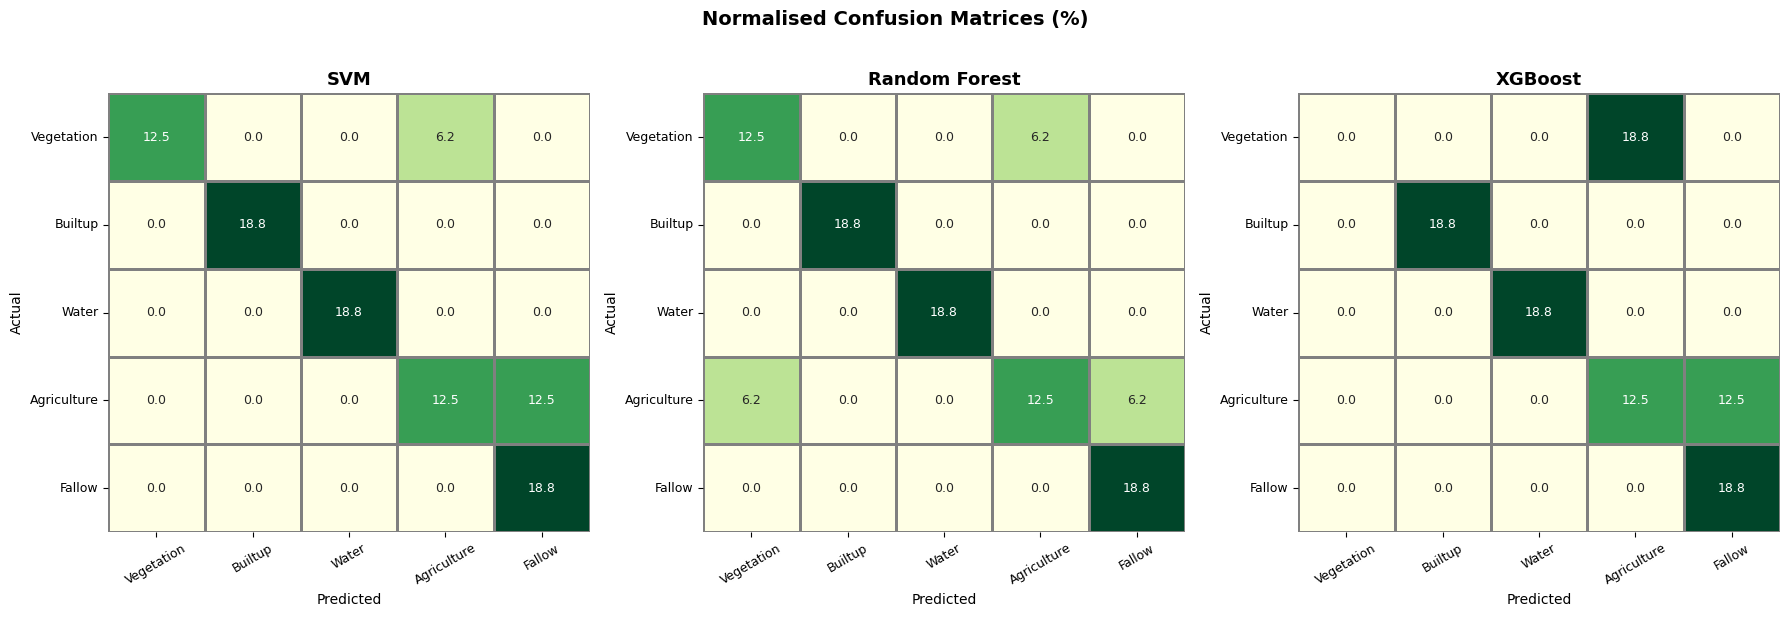

In [ ]:
# Confusion matrices – side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (name, y_pred) in zip(axes, [('SVM', svm_pred),
                                       ('Random Forest', rf_pred),
                                       ('XGBoost', xgb_pred)]):
    cm = confusion_matrix(y_test, y_pred)
    cm_pct = cm.astype(float) / cm.sum() * 100
    sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='YlGn',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                linewidths=1, linecolor='grey', cbar=False, ax=ax,
                annot_kws={'size': 9})
    ax.set_title(name, fontsize=13, fontweight='bold')
    ax.set_xlabel('Predicted', fontsize=10)
    ax.set_ylabel('Actual', fontsize=10)
    ax.tick_params(axis='x', rotation=30, labelsize=9)
    ax.tick_params(axis='y', rotation=0,  labelsize=9)

plt.suptitle('Normalised Confusion Matrices (%)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 6 · LULC Map Generation

Apply the best-performing model to the full scene to produce a Land Use / Land Cover map.

In [ ]:
# ─── Reconstruct stacked raster for full-scene prediction ────
img_full = rxr.open_rasterio(RASTER_PATH).assign_coords(band=['B8A','B4','B3','B2'])
img_full = img_full.astype(float) / 10000.0

nir_f, red_f, green_f, blue_f = (img_full.sel(band=b) for b in ['B8A','B4','B3','B2'])

def _band(da, name): return da.expand_dims({'band': [name]})

stacked_full = xr.concat([
    img_full,
    _band((nir_f - red_f) / (nir_f + red_f), 'NDVI'),
    _band((green_f - nir_f) / (green_f + nir_f), 'NDWI'),
    _band(1.5 * (nir_f - red_f) / (nir_f + red_f + 0.5), 'SAVI'),
    _band((2.5*(nir_f-red_f)/(nir_f+6*red_f-7.5*blue_f+1)).clip(-2,2), 'EVI'),
], dim='band')

arr = stacked_full.values                     # (8, H, W)
n_feats, H, W = arr.shape
arr_flat = arr.reshape(n_feats, -1).T         # (H*W, 8)
valid    = np.all(np.isfinite(arr_flat), axis=1)

print(f"Image size   : {H} × {W} = {H*W:,} pixels")
print(f"Valid pixels : {valid.sum():,}  ({valid.mean()*100:.1f}%)")


Image size   : 1938 × 2202 = 4,267,476 pixels
Valid pixels : 4,267,476  (100.0%)


In [ ]:
%%time
# Predict with best RF (fastest among the three)
pred_flat = np.zeros(H * W, dtype=np.uint8)
pred_flat[valid] = best_rf.predict(arr_flat[valid])

lulc_map_rf = pred_flat.reshape(H, W)
print("RF prediction done.")

# Also predict with XGBoost
pred_flat_xgb = np.zeros(H * W, dtype=np.uint8)
pred_flat_xgb[valid] = best_xgb.predict(arr_flat[valid]) + 1   # shift back to 1-based

lulc_map_xgb = pred_flat_xgb.reshape(H, W)
print("XGBoost prediction done.")


RF prediction done.
XGBoost prediction done.
CPU times: user 21.2 s, sys: 3.1 s, total: 24.3 s
Wall time: 19.1 s


In [ ]:
# Save classification maps as GeoTIFF using rioxarray
for clf_name, lulc_arr in [('RF', lulc_map_rf), ('XGBoost', lulc_map_xgb)]:
    pred_da = xr.DataArray(
        lulc_arr.astype(np.uint8)[np.newaxis, :, :],
        dims=['band', 'y', 'x'],
        coords={'band': [1], 'y': stacked_full.y, 'x': stacked_full.x}
    )
    pred_da = pred_da.rio.write_crs(stacked_full.rio.crs)
    pred_da = pred_da.rio.write_nodata(0)
    out_path = f'/content/lulc_{clf_name.lower()}.tif'
    pred_da.rio.to_raster(out_path)
    print(f"Saved → {out_path}")


Saved → /content/lulc_rf.tif
Saved → /content/lulc_xgboost.tif


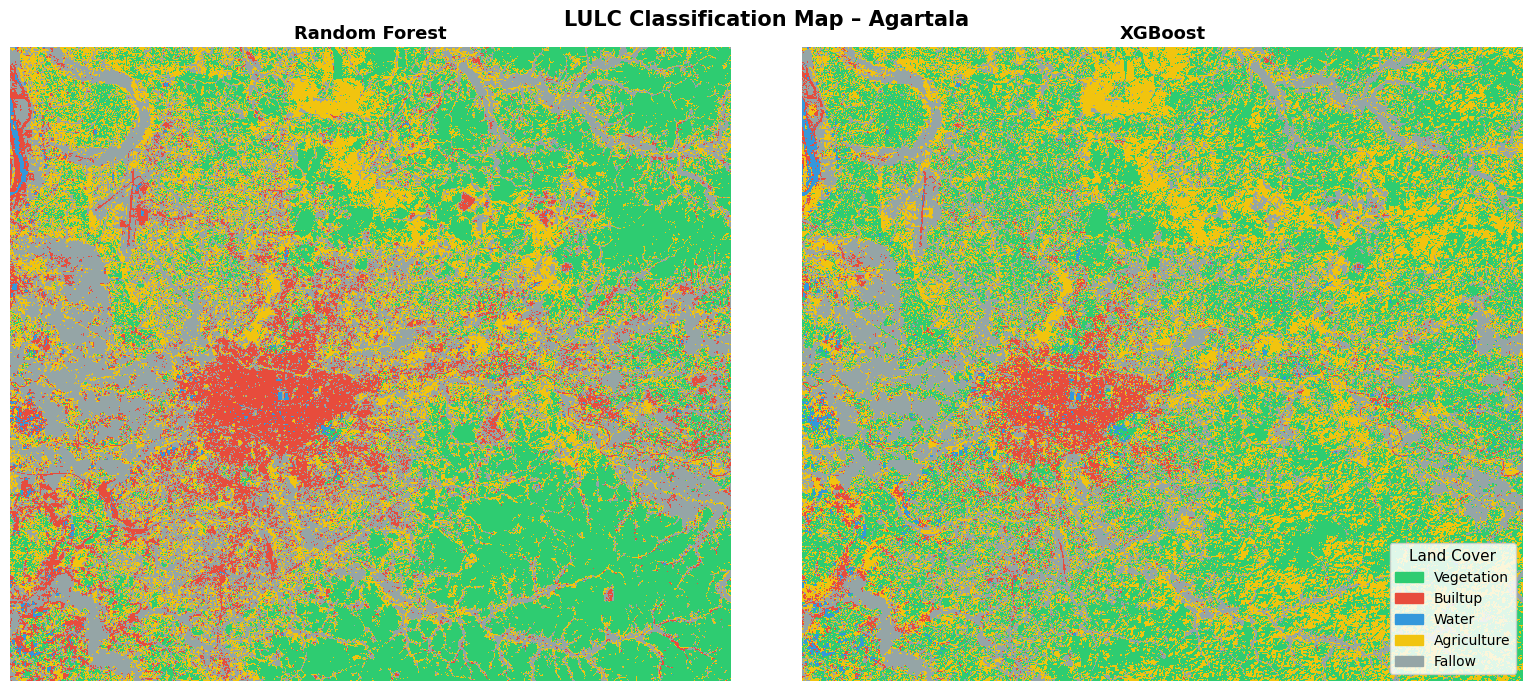

In [ ]:
# Visualise LULC maps
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm

LULC_COLORS = ['black', '#2ECC71', '#E74C3C', '#3498DB', '#F1C40F', '#95A5A6']
cmap = ListedColormap(LULC_COLORS)
norm = BoundaryNorm([0, 1, 2, 3, 4, 5, 6], len(LULC_COLORS))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, (title, lulc) in zip(axes, [('Random Forest', lulc_map_rf),
                                      ('XGBoost', lulc_map_xgb)]):
    im = ax.imshow(lulc, cmap=cmap, norm=norm, interpolation='nearest')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_axis_off()

# Shared legend
patches = [mpatches.Patch(color=c, label=l)
           for c, l in zip(LULC_COLORS[1:], list(CLASS_MAP.values()))]
axes[1].legend(handles=patches, loc='lower right',
               fontsize=10, title='Land Cover', title_fontsize=11,
               framealpha=0.85)

plt.suptitle('LULC Classification Map – Agartala', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


## Summary

| Classifier | Best CV Accuracy | Hyperparameters tuned |
|------------|------------------|-----------------------|
| SVM        | see output above | C, kernel, gamma |
| Random Forest | see above     | n_estimators, max_depth, max_features |
| XGBoost    | see above        | n_estimators, max_depth, learning_rate, subsample |

**Next → Notebook 3:** Explain *why* each model predicts what it does using feature importance and SHAP.
